<h1>Level A</h1>

<h4>1.1 Level A</h4>

In [71]:
import os
import kagglehub
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.impute import KNNImputer
%matplotlib inline

In [72]:
kagglehub.login()
path = kagglehub.dataset_download("beamhonor0911/youtube-trending-video-statistics-analytics")

In [73]:
files = os.listdir(path)
df = pd.read_csv(os.path.join(path, "global_youtube_statistics_2023.csv") , encoding="windows-1251")

df.info()
df.tail()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 995 entries, 0 to 994
Data columns (total 28 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   rank                                     995 non-null    int64  
 1   Youtuber                                 995 non-null    object 
 2   subscribers                              995 non-null    int64  
 3   video views                              995 non-null    float64
 4   category                                 949 non-null    object 
 5   Title                                    995 non-null    object 
 6   uploads                                  995 non-null    int64  
 7   Country                                  873 non-null    object 
 8   Abbreviation                             873 non-null    object 
 9   channel_type                             965 non-null    object 
 10  video_views_rank                         994 non-n

,rank,Youtuber,subscribers,video views,category,Title,uploads,Country,Abbreviation,channel_type,...,subscribers_for_last_30_days,created_year,created_month,created_date,Gross tertiary education enrollment (%),Population,Unemployment rate,Urban_population,Latitude,Longitude
990,991,Natan por Aпї,12300000,9.029610e+09,Sports,Natan por Aпї,1200,Brazil,BR,Entertainment,...,700000.0,2017.0,Feb,12.0,51.3,2.125594e+08,12.08,183241641.0,-14.235004,-51.925280
991,992,Free Fire India Official,12300000,1.674410e+09,People & Blogs,Free Fire India Official,1500,India,IN,Games,...,300000.0,2018.0,Sep,14.0,28.1,1.366418e+09,5.36,471031528.0,20.593684,78.962880
992,993,Panda,12300000,2.214684e+09,NaN,HybridPanda,2452,United Kingdom,GB,Games,...,1000.0,2006.0,Sep,11.0,60.0,6.683440e+07,3.85,55908316.0,55.378051,-3.435973
993,994,RobTopGames,12300000,3.741235e+08,Gaming,RobTopGames,39,Sweden,SE,Games,...,100000.0,2012.0,May,9.0,67.0,1.028545e+07,6.48,9021165.0,60.128161,18.643501
994,995,Make Joke Of,12300000,2.129774e+09,Comedy,Make Joke Of,62,India,IN,Comedy,...,100000.0,2017.0,Aug,1.0,28.1,1.366418e+09,5.36,471031528.0,20.593684,78.962880


| Attribute                                 | Type           | Reason                                                  |
| ----------------------------------------- | -------------- | ------------------------------------------------------- |
| `rank`                                    | **Ordinal**    | Represents ordered position/ranking                     |
| `Youtuber`                                | **Nominal**    | Names/identifiers of YouTubers                          |
| `subscribers`                             | **Discrete**   | Count of subscribers                                    |
| `video views`                             | **Discrete**   | Count of video views, despite being stored as `float64` |
| `category`                                | **Nominal**    | Categories such as Music, Gaming, Education             |
| `Title`                                   | **Nominal**    | Names/titles of channels                                |
| `uploads`                                 | **Discrete**   | Count of uploaded videos                                |
| `Country`                                 | **Nominal**    | Country names have no inherent order                    |
| `Abbreviation`                            | **Nominal**    | Country codes have no inherent order                    |
| `channel_type`                            | **Nominal**    | Types/categories of channels                            |
| `video_views_rank`                        | **Ordinal**    | Ranking based on video views                            |
| `country_rank`                            | **Ordinal**    | Ranking within a country                                |
| `channel_type_rank`                       | **Ordinal**    | Ranking within a channel type                           |
| `video_views_for_the_last_30_days`        | **Discrete**   | Number of views during 30 days                          |
| `lowest_monthly_earnings`                 | **Continuous** | Monetary amount can take decimal values                 |
| `highest_monthly_earnings`                | **Continuous** | Monetary amount can take decimal values                 |
| `lowest_yearly_earnings`                  | **Continuous** | Monetary amount can take decimal values                 |
| `highest_yearly_earnings`                 | **Continuous** | Monetary amount can take decimal values                 |
| `subscribers_for_last_30_days`            | **Discrete**   | Number of subscribers gained                            |
| `created_year`                            | **Discrete**   | Year is represented as a countable integer value        |
| `created_month`                           | **Nominal**    | Months are labels rather than quantities                |
| `created_date`                            | **Discrete**   | Represents a calendar date                              |
| `Gross tertiary education enrollment (%)` | **Continuous** | Percentage can have decimal values                      |
| `Population`                              | **Discrete**   | Population is a count of people                         |
| `Unemployment rate`                       | **Continuous** | Percentage/rate can have decimal values                 |
| `Urban_population`                        | **Discrete**   | Count of people living in urban areas                   |
| `Latitude`                                | **Continuous** | Geographic coordinate can take decimal values           |
| `Longitude`                               | **Continuous** | Geographic coordinate can take decimal values           |


<h4>1.2 Level A</h4>


,Mean,Median,Mode,Range,Variance,Std,IQR
rank,4.980000e+02,4.980000e+02,1.000000e+00,9.940000e+02,8.258500e+04,2.873761e+02,4.970000e+02
subscribers,2.298241e+07,1.770000e+07,1.250000e+07,2.327000e+08,3.071644e+14,1.752611e+07,1.010000e+07
video views,1.103954e+10,7.760820e+09,0.000000e+00,2.280000e+11,1.991159e+20,1.411084e+10,9.266556e+09
uploads,9.187126e+03,7.290000e+02,0.000000e+00,3.013080e+05,1.166315e+09,3.415135e+04,2.473000e+03
video_views_rank,5.542489e+05,9.155000e+02,4.057944e+06,4.057943e+06,1.857175e+12,1.362782e+06,3.261500e+03
country_rank,3.860535e+02,5.100000e+01,1.000000e+00,7.740000e+03,1.518427e+06,1.232245e+03,1.120000e+02
channel_type_rank,7.457193e+02,6.550000e+01,1.000000e+00,7.740000e+03,3.780639e+06,1.944387e+03,1.127500e+02
video_views_for_the_last_30_days,1.756103e+08,6.408500e+07,1.000000e+00,6.589000e+09,1.733708e+17,4.163782e+08,1.486890e+08
lowest_monthly_earnings,3.688615e+04,1.330000e+04,0.000000e+00,8.509000e+05,5.163676e+09,7.185872e+04,3.520000e+04
highest_monthly_earnings,5.898078e+05,2.127000e+05,0.000000e+00,1.360000e+07,1.319334e+12,1.148622e+06,5.633000e+05


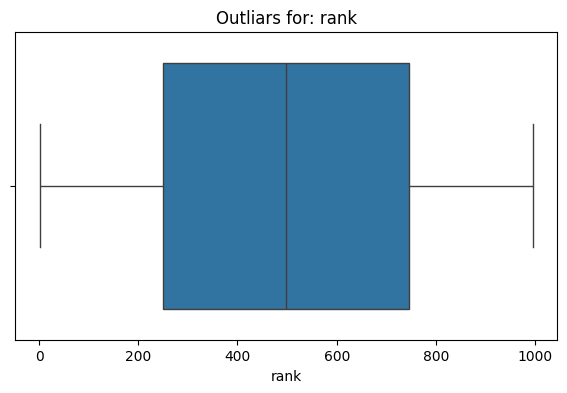

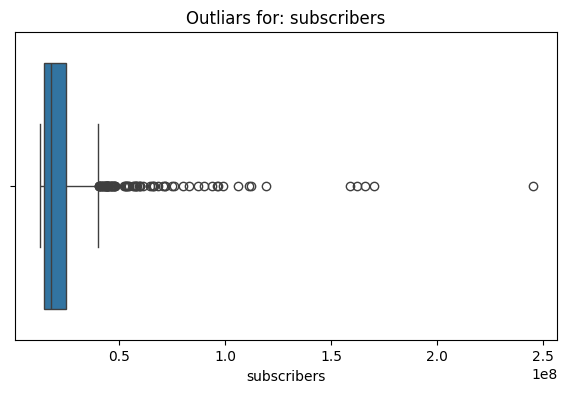

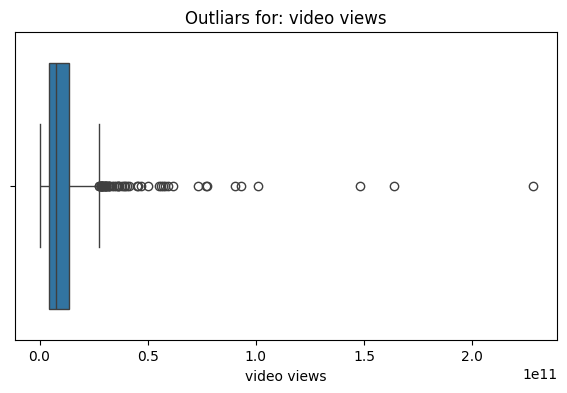

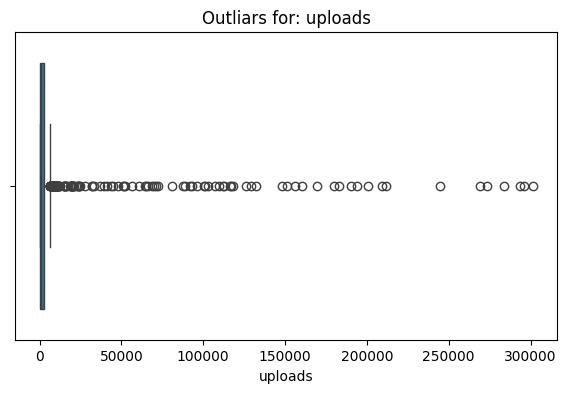

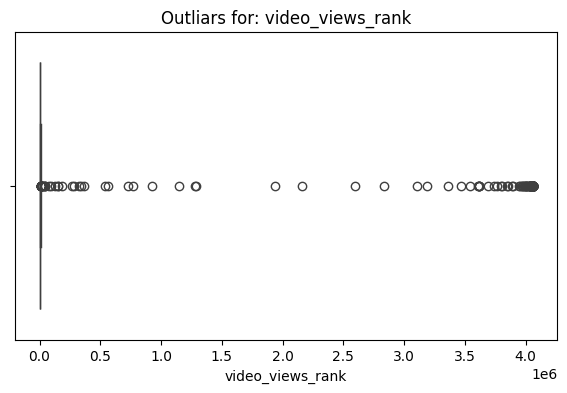

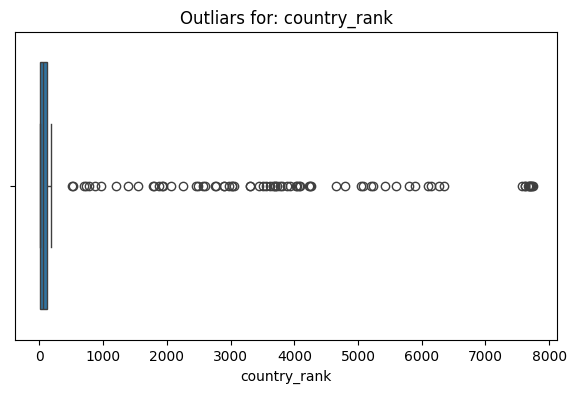

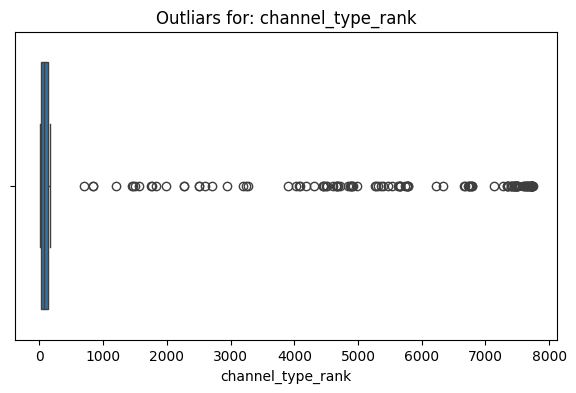

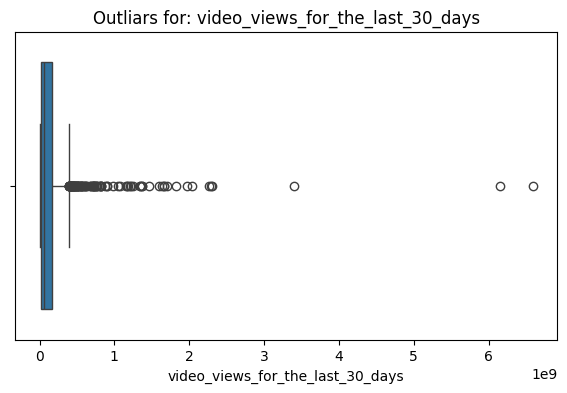

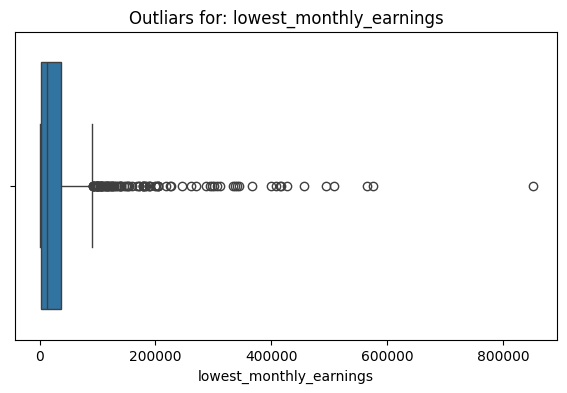

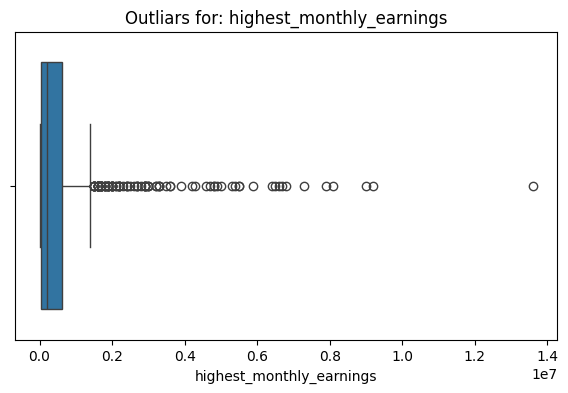

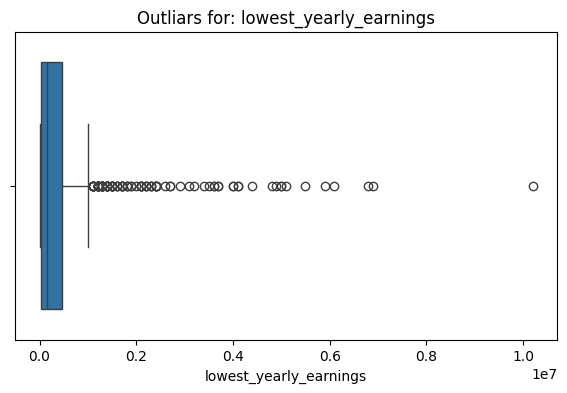

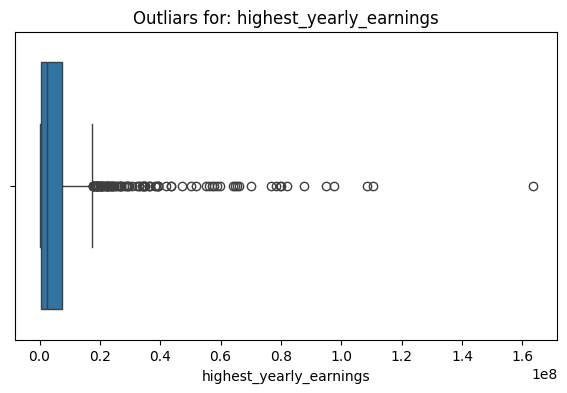

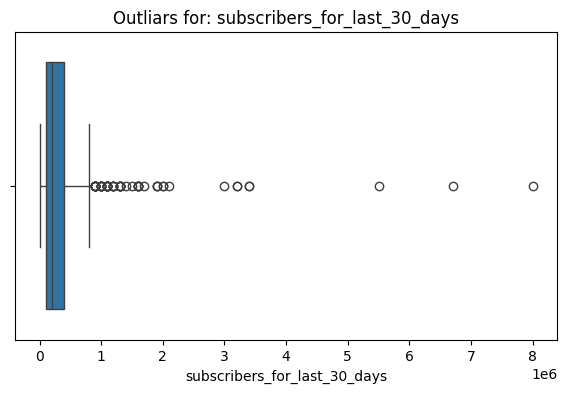

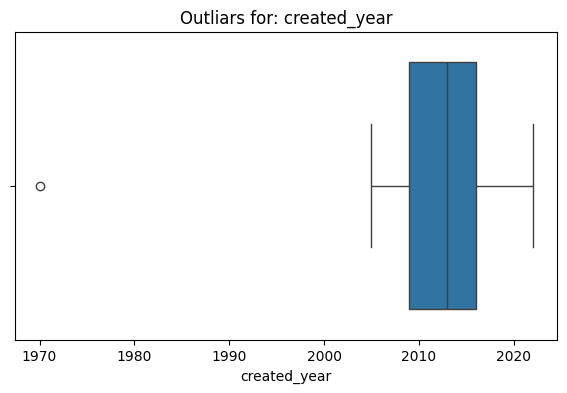

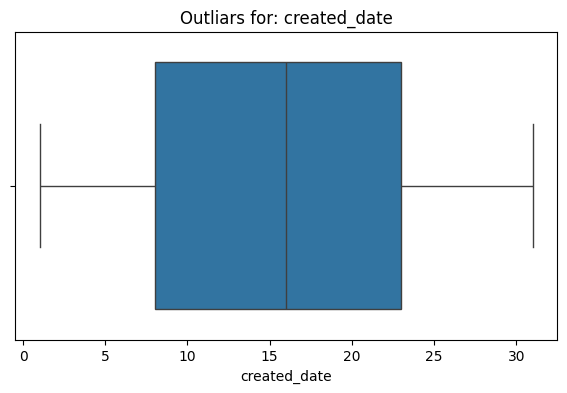

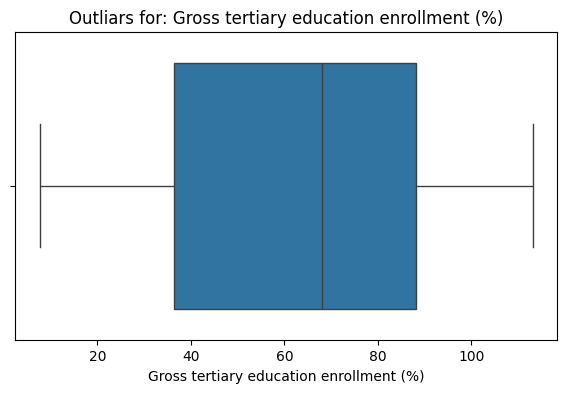

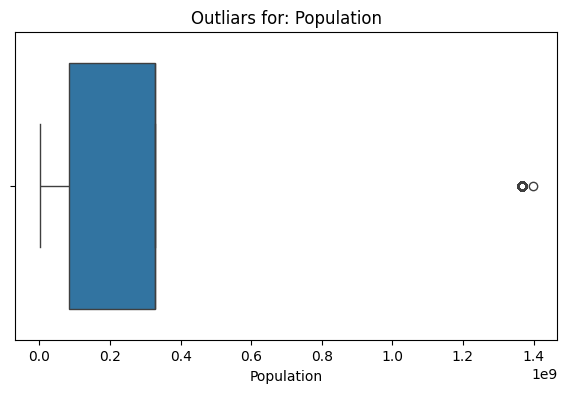

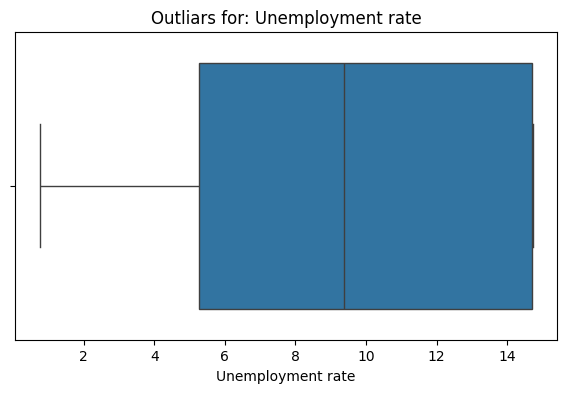

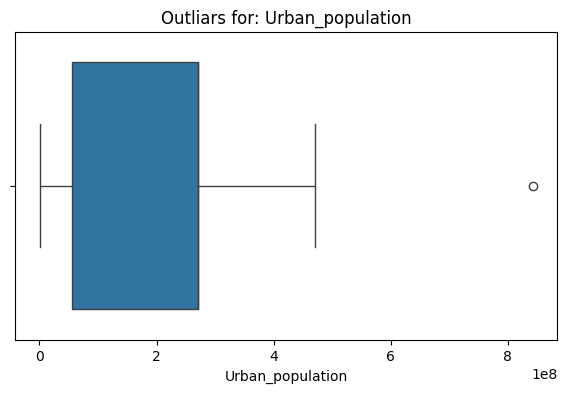

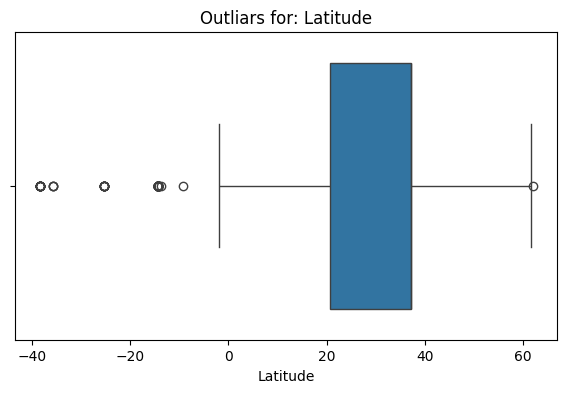

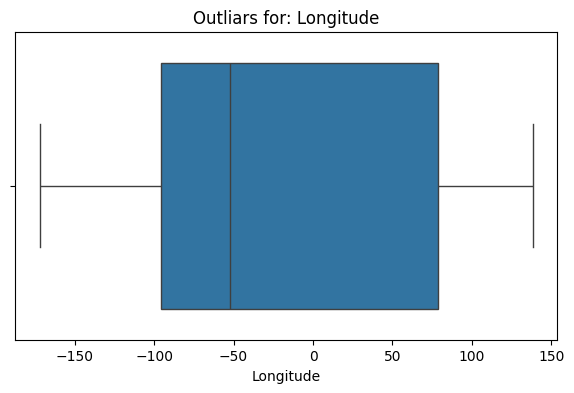

In [74]:
numeric_features = df.select_dtypes(include="number").columns

mean = df[numeric_features].mean()
median = df[numeric_features].median()
mode = df[numeric_features].mode().iloc[0]
range = df[numeric_features].max() - df[numeric_features].min()
variance = df[numeric_features].var()
std = df[numeric_features].std()
IQR = df[numeric_features].quantile(0.75) - df[numeric_features].quantile(0.25)

df_ctd = pd.DataFrame({
    "Mean":mean,
    "Median":median,
    "Mode":mode,
    "Range":range,
    "Variance":variance,
    "Std":std,
    "IQR":IQR
})

display(df_ctd)

for column in numeric_features:
    plt.figure(figsize=(7,4))
    sns.boxplot(x=df[column])
    plt.title(f"Outliars for: {column}")
    plt.show()

<h4>1.3 Level A</h4>

In [75]:
#Check missing values before imputation
missing_values = df.isnull().sum()
print("Missing Values Before Imputation:\n", missing_values)
print("--------------------------------------------------------------------------------------------------------------------------------------------------------------------")
print("Missing Percent Before Imputation:\n", (missing_values/len(df) * 100).round(2))

object_features = df.select_dtypes(include="object").columns
numeric_features = df.select_dtypes(include="number").columns


Missing Values Before Imputation:
 rank                                         0
Youtuber                                     0
subscribers                                  0
video views                                  0
category                                    46
Title                                        0
uploads                                      0
Country                                    122
Abbreviation                               122
channel_type                                30
video_views_rank                             1
country_rank                               116
channel_type_rank                           33
video_views_for_the_last_30_days            56
lowest_monthly_earnings                      0
highest_monthly_earnings                     0
lowest_yearly_earnings                       0
highest_yearly_earnings                      0
subscribers_for_last_30_days               337
created_year                                 5
created_month            

In [76]:
#Filling with constant values
df_impute_constants = df.copy()
constant_imputer_object = SimpleImputer(strategy='constant' , fill_value="Unknown")
constant_imputer_numeric = SimpleImputer(strategy='constant' , fill_value = 0)

df_impute_constants[object_features] = constant_imputer_object.fit_transform(df_impute_constants[object_features])
df_impute_constants[numeric_features] = constant_imputer_numeric.fit_transform(df_impute_constants[numeric_features])

#Check missing values after imputation with constant values
missing_values = df_impute_constants.isnull().sum()
print("Missing Values After Imputation(Constants):\n", missing_values)
print("--------------------------------------------------------------------------------------------------------------------------------------------------------------------")
print("Missing Percent After Imputation(Constants):\n", (missing_values/len(df) * 100).round(2))

Missing Values After Imputation(Constants):
 rank                                       0
Youtuber                                   0
subscribers                                0
video views                                0
category                                   0
Title                                      0
uploads                                    0
Country                                    0
Abbreviation                               0
channel_type                               0
video_views_rank                           0
country_rank                               0
channel_type_rank                          0
video_views_for_the_last_30_days           0
lowest_monthly_earnings                    0
highest_monthly_earnings                   0
lowest_yearly_earnings                     0
highest_yearly_earnings                    0
subscribers_for_last_30_days               0
created_year                               0
created_month                              0
created_da

In [77]:
#Filling the numeric values with mean and object values with mode
df_impute_mean_mode = df.copy()
mode_imputer_object = SimpleImputer(strategy='most_frequent')
mean_imputer_numeric = SimpleImputer(strategy='mean')

df_impute_mean_mode[object_features] = mode_imputer_object.fit_transform(df_impute_mean_mode[object_features])
df_impute_mean_mode[numeric_features] = mean_imputer_numeric.fit_transform(df_impute_mean_mode[numeric_features])

missing_values = df_impute_mean_mode.isnull().sum()
print("Missing Values After Imputation(Mean and Mode):\n", missing_values)
print("--------------------------------------------------------------------------------------------------------------------------------------------------------------------")
print("Missing Percent After Imputation(Mean and Mode):\n", (missing_values/len(df) * 100).round(2))


Missing Values After Imputation(Mean and Mode):
 rank                                       0
Youtuber                                   0
subscribers                                0
video views                                0
category                                   0
Title                                      0
uploads                                    0
Country                                    0
Abbreviation                               0
channel_type                               0
video_views_rank                           0
country_rank                               0
channel_type_rank                          0
video_views_for_the_last_30_days           0
lowest_monthly_earnings                    0
highest_monthly_earnings                   0
lowest_yearly_earnings                     0
highest_yearly_earnings                    0
subscribers_for_last_30_days               0
created_year                               0
created_month                              0
create

In [78]:
df_imputed = df.copy()

imputer_KNN = KNNImputer(n_neighbors=7)
imputer_Simple = SimpleImputer(strategy="most_frequent")

df_imputed[numeric_features] = imputer_KNN.fit_transform(
    df_imputed[numeric_features]
)

df_imputed[object_features] = imputer_Simple.fit_transform(
    df_imputed[object_features]
)

missing_values = df_imputed.isnull().sum()

print("Missing Values After Imputation:\n", missing_values)

print("-" * 150)

print(
    "Missing Percent After Imputation:\n",
    (missing_values / len(df_imputed) * 100).round(2)
)

Missing Values After Imputation:
 rank                                       0
Youtuber                                   0
subscribers                                0
video views                                0
category                                   0
Title                                      0
uploads                                    0
Country                                    0
Abbreviation                               0
channel_type                               0
video_views_rank                           0
country_rank                               0
channel_type_rank                          0
video_views_for_the_last_30_days           0
lowest_monthly_earnings                    0
highest_monthly_earnings                   0
lowest_yearly_earnings                     0
highest_yearly_earnings                    0
subscribers_for_last_30_days               0
created_year                               0
created_month                              0
created_date         

In [79]:
#Comparison of mean and std BEFORE VS AFTER

comparison = pd.DataFrame({
    "Mean Before": df[numeric_features].mean(),
    "Mean After": df_imputed[numeric_features].mean(),
    "Std Before": df[numeric_features].std(),
    "Std After": df_imputed[numeric_features].std()
})

comparison.round(2)

comparison["Mean Change"] = (
    comparison["Mean After"] - comparison["Mean Before"]
)

comparison["Std Change"] = (
    comparison["Std After"] - comparison["Std Before"]
)

comparison.round(2)

,Mean Before,Mean After,Std Before,Std After,Mean Change,Std Change
rank,4.980000e+02,4.980000e+02,2.873800e+02,2.873800e+02,0.00,0.00
subscribers,2.298241e+07,2.298241e+07,1.752611e+07,1.752611e+07,0.00,0.00
video views,1.103954e+10,1.103954e+10,1.411084e+10,1.411084e+10,0.00,0.00
uploads,9.187130e+03,9.187130e+03,3.415135e+04,3.415135e+04,0.00,0.00
video_views_rank,5.542489e+05,5.554423e+05,1.362782e+06,1.362617e+06,1193.41,-165.58
country_rank,3.860500e+02,4.056700e+02,1.232240e+03,1.179290e+03,19.61,-52.96
channel_type_rank,7.457200e+02,7.567500e+02,1.944390e+03,1.920870e+03,11.04,-23.52
video_views_for_the_last_30_days,1.756103e+08,1.770950e+08,4.163782e+08,4.126453e+08,1484687.32,-3732840.17
lowest_monthly_earnings,3.688615e+04,3.688615e+04,7.185872e+04,7.185872e+04,0.00,0.00
highest_monthly_earnings,5.898078e+05,5.898078e+05,1.148622e+06,1.148622e+06,0.00,0.00


**Constant value**

Advantages:

Simple and fast.
Easy to implement.
Does not require complex calculations.

Disadvantages:

Can significantly change the mean.
Can reduce or distort standard deviation.
Using 0 may create unrealistic values.

**Mean/Median/Mode**

Advantages:

Very simple and computationally efficient.
Mean works well for relatively symmetric numerical data.
Median is more resistant to outliers.
Mode is suitable for categorical variables.

Disadvantages:

Reduces variability in the data.
Does not account for relationships between variables.
Mean can be affected by outliers.

**KNN / Predictive imputation**

Advantages:

Uses relationships between observations.
Usually preserves the structure of the data better than constant imputation.
Can produce more realistic values.

Disadvantages:

More computationally expensive.
Results depend on the choice of n_neighbors.
Sensitive to the scale of numerical variables.
More complicated than simple imputation.


# Level B 

In [80]:
# Loading new dataset

kagglehub.login()
path = kagglehub.dataset_download("razanihababdellatif/coffee-quality-and-pricing-benchmark")
files = os.listdir(path)
df2 = pd.read_csv(os.path.join(path, "coffee_value_benchmark.csv"))



### 2.1 Level B

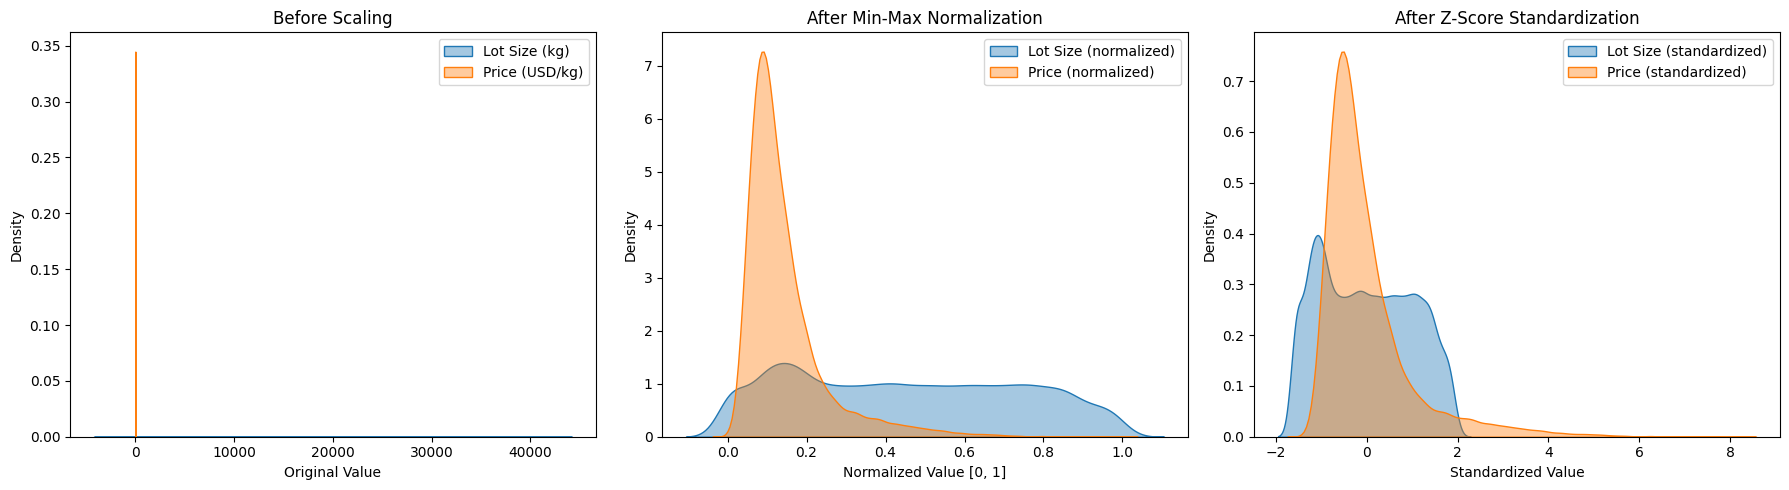

In [81]:
# Min-Max Normalization and Z-Score Standardization

from sklearn.preprocessing import MinMaxScaler, StandardScaler

columns_for_normalization = ['lot_size_kg', 'price_usd_per_kg']

# Apply Min-Max Scaling
min_max_scaler = MinMaxScaler()
z_score_scaler = StandardScaler()

df_min_max_scaled = pd.DataFrame(
    min_max_scaler.fit_transform(df2[columns_for_normalization]),
    columns=columns_for_normalization
)

# Apply Z-Score Standardization
df_z_score_scaled = pd.DataFrame(
    z_score_scaler.fit_transform(df2[columns_for_normalization]),
    columns=columns_for_normalization
)

# Plot KDE distributions
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Before Normalization
sns.kdeplot(
    df2['lot_size_kg'],
    fill=True,
    alpha=0.4,
    label='Lot Size (kg)',
    ax=axes[0]
)

sns.kdeplot(
    df2['price_usd_per_kg'],
    fill=True,
    alpha=0.4,
    label='Price (USD/kg)',
    ax=axes[0]
)

axes[0].set_title('Before Scaling')
axes[0].set_xlabel('Original Value')
axes[0].set_ylabel('Density')
axes[0].legend()

# After Min-Max Normalization
sns.kdeplot(
    df_min_max_scaled['lot_size_kg'],
    fill=True,
    alpha=0.4,
    label='Lot Size (normalized)',
    ax=axes[1]
)

sns.kdeplot(
    df_min_max_scaled['price_usd_per_kg'],
    fill=True,
    alpha=0.4,
    label='Price (normalized)',
    ax=axes[1]
)

axes[1].set_title('After Min-Max Normalization')
axes[1].set_xlabel('Normalized Value [0, 1]')
axes[1].set_ylabel('Density')
axes[1].legend()

# After Z-Score Standardization
sns.kdeplot(
    df_z_score_scaled['lot_size_kg'],
    fill=True,
    alpha=0.4,
    label='Lot Size (standardized)',
    ax=axes[2]
)

sns.kdeplot(
    df_z_score_scaled['price_usd_per_kg'],
    fill=True,
    alpha=0.4,
    label='Price (standardized)',
    ax=axes[2]
)

axes[2].set_title('After Z-Score Standardization')
axes[2].set_xlabel('Standardized Value')
axes[2].set_ylabel('Density')
axes[2].legend()

plt.tight_layout()
plt.show()

### When each method is preferable

* **Min-Max Normalization** is preferable when you need all features to be scaled to a fixed range, usually **[0, 1]**. It is useful for algorithms that are sensitive to feature ranges, such as **K-Nearest Neighbors (KNN), neural networks, and some distance-based methods**. However, it can be sensitive to outliers.

* **Z-Score Standardization** is preferable when you want features to have a **mean of 0 and a standard deviation of 1**. It is commonly used when features have different scales and when the data is approximately normally distributed. It is useful for methods such as **logistic regression, linear regression, SVM, and PCA**.

* **Before scaling**, the original data should be kept when the actual units and original interpretation are important. Scaling is mainly needed when differences in feature magnitudes could affect the model or analysis.


### 2.2 Level B

In [82]:
#New Feature
df2['Total_Value_Usd'] = df2['lot_size_kg'] * df2['price_usd_per_kg']
df2[['Total_Value_Usd' , 'lot_size_kg','price_usd_per_kg']].head(5)

labels = ["Very Small", "Small", "Medium", "Large", "Very Large"]

#Equal-width Binning
df2['price_usd_per_kg'].describe()
df2['price_equal_width'] = pd.cut(df2['price_usd_per_kg'] , bins=5,labels=labels)

print(df2["price_equal_width"].value_counts().sort_index())

#Equal-frequency Binning
df2['lot_size_frequency'] = pd.qcut(df2['lot_size_kg'],q=5,labels=labels)

print(df2["lot_size_frequency"].value_counts().sort_index())

df2[['price_usd_per_kg','lot_size_kg','lot_size_frequency','price_equal_width']].head()


#One-Hot Encoding
categorical_columns = df2.select_dtypes(include="object").columns
df2[categorical_columns].head()

df_encoded = pd.get_dummies(df2, columns=["species", "processing_method"])
df_encoded.head()


price_equal_width
Very Small    29393
Small          4922
Medium         1150
Large           219
Very Large       16
Name: count, dtype: int64
lot_size_frequency
Very Small    7140
Small         7141
Medium        7139
Large         7140
Very Large    7140
Name: count, dtype: int64


,record_id,lot_id,harvest_season,harvest_calendar_year,harvest_month,country_of_origin,farm_type,farm_size_hectares,tree_age_years,altitude_mean_meters,...,price_usd_per_kg,Total_Value_Usd,price_equal_width,lot_size_frequency,species_Arabica,species_Robusta,processing_method_Anaerobic,processing_method_Honey,processing_method_Natural,processing_method_Washed
0,REC-0000001,LOT-0032936,2020/21,2020,10,Vietnam,Smallholder,0.58,28.0,1961.0,...,2.43,64232.19,Very Small,Large,True,False,False,False,True,False
1,REC-0000002,LOT-0030952,2021/22,2022,1,Honduras,Smallholder,1.12,2.0,1257.0,...,4.06,103310.76,Very Small,Large,True,False,True,False,False,False
2,REC-0000003,LOT-0018572,2020/21,2020,11,Vietnam,Cooperative,13.82,5.0,557.0,...,4.26,66911.82,Very Small,Medium,False,True,False,False,False,True
3,REC-0000004,LOT-0005318,2021/22,2021,10,Vietnam,Cooperative,9.96,22.0,652.0,...,3.60,10364.40,Very Small,Very Small,False,True,False,False,False,True
4,REC-0000005,LOT-0006317,2021/22,2021,7,Brazil,Smallholder,1.90,11.0,971.0,...,4.16,39773.76,Very Small,Small,False,True,False,True,False,False


### Impact of Transformations on ML Models

These transformations can help machine learning models work better with the data.

* **Feature engineering** adds new useful information to the dataset.
* **Discretization** groups continuous values into categories, which can make the data easier to understand, but some exact information is lost.
* **One-hot encoding** converts categorical data into numerical columns, so ML models can use them.
* One-hot encoding can create many new columns if there are many categories.
* Overall, these transformations can improve the data for ML models, but they can also cause information loss or increase the number of features.


# Level (Additional Analytical Tasks)



### 3.1 Level(Additional Analytical Tasks)

In [83]:
#Two Vectors
vector_1 = np.array([1,2,3,4,5])
vector_2 = np.array([2,4,6,8,10])

#Euclidean Distance
euclidean_distance = np.sqrt(np.sum((vector_1-vector_2)**2))
print("Euclidean distance:", euclidean_distance)

#Jaccard Similarity
set_1 = {1,2,3,4}
set_2 = {2,4,6,8}

intersection = len(set_1 & set_2)
union = len(set_1 | set_2)

jaccard_similarity = intersection / union
print('Jaccard Similarity:', jaccard_similarity)

#Cosine Similarity
dot_product = np.sum(vector_1 * vector_2)

length_vector_1 = np.sqrt(np.sum(vector_1**2))
length_vector_2 = np.sqrt(np.sum(vector_2**2))

cosine_similarity = dot_product / (length_vector_1 * length_vector_2)
print("Cosine Similarity:",cosine_similarity)

#Pearson Correlation
vector_1_mean = np.mean(vector_1)
vector_2_mean = np.mean(vector_2)
numerator = np.sum((vector_1 - vector_1_mean) * (vector_2 - vector_2_mean))

denominator = np.sqrt(
    np.sum((vector_1 - vector_1_mean) ** 2) *
    np.sum((vector_2 - vector_2_mean) ** 2)
)

pearson = numerator / denominator

print("Pearson correlation:", pearson)

Euclidean distance: 7.416198487095663
Jaccard Similarity: 0.3333333333333333
Cosine Similarity: 1.0
Pearson correlation: 1.0


### Explanation of the Metrics

**Euclidean Distance** measures the straight-line distance between two numeric vectors. A smaller value means that the vectors are closer to each other.

**Jaccard Similarity** measures how many elements two sets have in common compared to the total number of unique elements. The value is between 0 and 1, where 1 means the sets are identical.

**Cosine Similarity** measures the angle between two vectors. A value close to 1 means that the vectors have a similar direction, while 0 means that they are perpendicular.

**Pearson Correlation** measures the strength and direction of the linear relationship between two numeric vectors. A value close to 1 means a strong positive relationship, while -1 means a strong negative relationship.

### Comparison of Results

The calculated results are approximately:

- Euclidean Distance = **7.416**
- Jaccard Similarity = **0.333**
- Cosine Similarity = **1.0**
- Pearson Correlation = **1.0**

The results are different because each metric measures a different type of similarity. Euclidean Distance measures the actual distance between values, while Jaccard measures common elements between sets. Cosine Similarity focuses on the direction of the vectors, and Pearson Correlation focuses on their linear relationship.

In this example, `vector_2` is exactly two times `vector_1`. Therefore, the vectors have the same direction and a perfect linear relationship, which gives Cosine Similarity and Pearson Correlation values close to 1. However, their actual values are different, so the Euclidean Distance is greater than 0.

### 3.2 Level(Additional Analytical Tasks)

Covariance Matrix:
[[ 1.00002801 -0.24767559  0.81591735]
 [-0.24767559  1.00002801  0.17268726]
 [ 0.81591735  0.17268726  1.00002801]]
Eigenvalues:
[0.08715307 1.81961796 1.093313  ]

Eigenvectors:
[[ 0.67894181  0.71424015 -0.16999714]
 [ 0.31009629 -0.06909095  0.94819129]
 [-0.66549103  0.69648219  0.26839196]]
Selected eigenvalues:
[1.81961796 1.093313  ]

Selected eigenvectors:
[[ 0.71424015 -0.16999714]
 [-0.06909095  0.94819129]
 [ 0.69648219  0.26839196]]
PCA shape: (35700, 2)
[[ 0.40913881 -1.22544359]
 [ 0.74687501 -0.33424876]
 [-0.28873111 -0.26472055]
 [-1.72302679 -0.60953573]
 [-0.98323419 -0.33690372]]


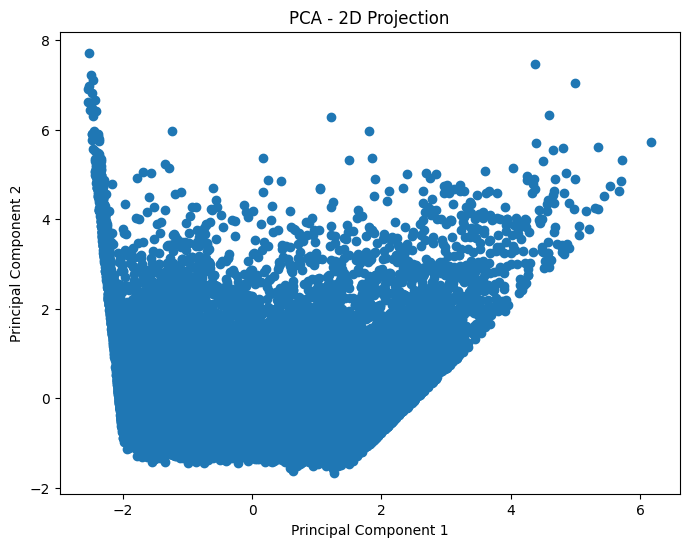

In [84]:
features = ["lot_size_kg", "price_usd_per_kg", "Total_Value_Usd"]

X = df2[features].values

# Apply Z-Score Standardization
df_z_score_scaled = pd.DataFrame(
    z_score_scaler.fit_transform(df2[features]),
    columns=features
)

# Compute the covariance matrix
cov_matrix = np.cov(
    df_z_score_scaled,
    rowvar=False
)

print("Covariance Matrix:")
print(cov_matrix)

# Find eigenvalues and eigenvectors
eigenvalues, eigenvectors = np.linalg.eig(cov_matrix)

print("Eigenvalues:")
print(eigenvalues)

print("\nEigenvectors:")
print(eigenvectors)

# Sort eigenvalues from largest to smallest
indices = np.argsort(eigenvalues)[::-1]

eigenvalues = eigenvalues[indices]
eigenvectors = eigenvectors[:, indices]

# Select the two largest eigenvectors
selected_eigenvectors = eigenvectors[:, :2]

print("Selected eigenvalues:")
print(eigenvalues[:2])

print("\nSelected eigenvectors:")
print(selected_eigenvectors)

# Project the standardized data onto the first two principal components
X_pca = df_z_score_scaled.values @ selected_eigenvectors

print("PCA shape:", X_pca.shape)
print(X_pca[:5])

plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1]
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA - 2D Projection")

plt.show()

### Explanation of PCA Steps

**1. Standardization**

The features are standardized using Z-score standardization. This puts all features on a similar scale with a mean close to 0 and a standard deviation close to 1.

**2. Covariance Matrix**

The covariance matrix shows how the features change together. It helps PCA identify the directions where the data has the most variation.

**3. Eigenvalues and Eigenvectors**

Eigenvalues show how much variance is explained by each principal component. Eigenvectors represent the directions of these principal components.

**4. Selecting the Largest Eigenvalues**

The eigenvalues are sorted from largest to smallest. The two largest eigenvalues are selected because their corresponding principal components contain the most variance.

**5. Projection**

The standardized data is projected onto the two selected eigenvectors. This transforms the original three-dimensional data into a two-dimensional representation with PC1 and PC2.

**6. Visualization**

The 2D scatter plot shows the data using the first two principal components. Each point represents one observation from the original dataset.


### Comparison of Original and Reduced Data

The original dataset contains three features: `lot_size_kg`, `price_usd_per_kg`, and `Total_Value_Usd`. Therefore, the original data has three dimensions.

After applying PCA, the data is represented by only two principal components: PC1 and PC2. These components are combinations of the original features.

The 2D projection is easier to visualize and can show the main structure and patterns in the data. However, some information is lost because one dimension was removed. PCA tries to keep the maximum possible variance in the two selected components.


# Level C


### 4.1 Level C

In [85]:
kagglehub.login()
path = kagglehub.dataset_download("sehaj1104/student-productivity-and-digital-distraction-dataset")
files = os.listdir(path)
df_lvlC = pd.read_csv(os.path.join(path, "student_productivity_distraction_dataset_20000.csv") , encoding="windows-1251")


In [86]:
print("Shape:", df_lvlC.shape)
print("\nColumns:")
print(df_lvlC.columns.tolist())




Shape: (20000, 18)

Columns:
['student_id', 'age', 'gender', 'study_hours_per_day', 'sleep_hours', 'phone_usage_hours', 'social_media_hours', 'youtube_hours', 'gaming_hours', 'breaks_per_day', 'coffee_intake_mg', 'exercise_minutes', 'assignments_completed', 'attendance_percentage', 'stress_level', 'focus_score', 'final_grade', 'productivity_score']


In [87]:
# Numerical variable: productivity_score
# Categorical variable: gender 
# Natural cluster identifiers: age (age_group) and stress_level (stress_group)

# Create groups
df_lvlC["age_group"] = pd.cut(
    df_lvlC["age"],
    bins=[0, 20, 23, 26, 30, 100],
    labels=["18-20", "21-23", "24-26", "27-30", "31+"]
)

print(df_lvlC["age_group"].value_counts().sort_index())

df_lvlC["stress_group"] = pd.cut(
    df_lvlC["stress_level"],
    bins=[0, 3, 6, 10],
    labels=["low", "medium", "high"]
)
print(df_lvlC["stress_group"].value_counts().sort_index())

age_group
18-20    6141
21-23    4647
24-26    4616
27-30    4596
31+         0
Name: count, dtype: int64
stress_group
low       6089
medium    5953
high      7958
Name: count, dtype: int64


In [88]:
# Simple Random Sample - 10%
simple_random_sample = df_lvlC.sample(
    frac=0.10,
    random_state=42
)

print("Full dataset:", len(df_lvlC))
print("Simple Random Sample:", len(simple_random_sample))

# Stratified Sample - 10%
stratified_sample = (
    df_lvlC.groupby("gender", group_keys=False)
      .sample(frac=0.10, random_state=42)
)

print("Stratified Sample:", len(stratified_sample))

print("Stratified Sample:", len(stratified_sample))

print("Full dataset:")
print(df_lvlC["gender"].value_counts(normalize=True))

print("\nStratified sample:")
print(stratified_sample["gender"].value_counts(normalize=True))

# Cluster Sampling
df_lvlC["cluster"] = (
    df_lvlC["age_group"].astype(str)
    + "_"
    + df_lvlC["stress_group"].astype(str)
)

print(df_lvlC["cluster"].value_counts().sort_index())
np.random.seed(42)

clusters = df_lvlC["cluster"].dropna().unique()

selected_clusters = np.random.choice(
    clusters,
    size=2,
    replace=False
)

cluster_sample = df_lvlC[
    df_lvlC["cluster"].isin(selected_clusters)
]

print("Selected clusters:", selected_clusters)
print("Cluster Sample:", len(cluster_sample))

# Sample size as a % of the full dataset, for comparison across methods
print("\nSample size as % of full dataset:")
print("Simple Random:", round(len(simple_random_sample) / len(df_lvlC) * 100, 1), "%")
print("Stratified:", round(len(stratified_sample) / len(df_lvlC) * 100, 1), "%")
print("Cluster:", round(len(cluster_sample) / len(df_lvlC) * 100, 1), "%")

Full dataset: 20000
Simple Random Sample: 2000
Stratified Sample: 2000
Stratified Sample: 2000
Full dataset:
gender
Female    0.4820
Male      0.4791
Other     0.0389
Name: proportion, dtype: float64

Stratified sample:
gender
Female    0.482
Male      0.479
Other     0.039
Name: proportion, dtype: float64
cluster
18-20_high      2477
18-20_low       1857
18-20_medium    1807
21-23_high      1854
21-23_low       1405
21-23_medium    1388
24-26_high      1810
24-26_low       1449
24-26_medium    1357
27-30_high      1817
27-30_low       1378
27-30_medium    1401
Name: count, dtype: int64
Selected clusters: ['18-20_low' '24-26_high']
Cluster Sample: 3667

Sample size as % of full dataset:
Simple Random: 10.0 %
Stratified: 10.0 %
Cluster: 18.3 %


In [89]:
#Compute descriptive statistics
def calculate_statistics(data, column):
    return pd.Series({
        "Mean": data[column].mean(),
        "Median": data[column].median(),
        "Variance": data[column].var(),
        "IQR": (
            data[column].quantile(0.75)
            - data[column].quantile(0.25)
        )
    })
#Create a comparison table
statistics = pd.DataFrame({
    "Full Dataset": calculate_statistics(
        df_lvlC, "productivity_score"
    ),

    "Simple Random": calculate_statistics(
        simple_random_sample,
        "productivity_score"
    ),

    "Stratified": calculate_statistics(
        stratified_sample,
        "productivity_score"
    ),

    "Cluster": calculate_statistics(
        cluster_sample,
        "productivity_score"
    )
})

print(statistics)

          Full Dataset  Simple Random  Stratified     Cluster
Mean         50.180419      49.659525    50.13421   50.463163
Median       50.235000      49.460000    50.58000   50.650000
Variance    258.780825     253.998726   250.15382  256.407300
IQR          23.082500      23.090000    22.26250   22.770000


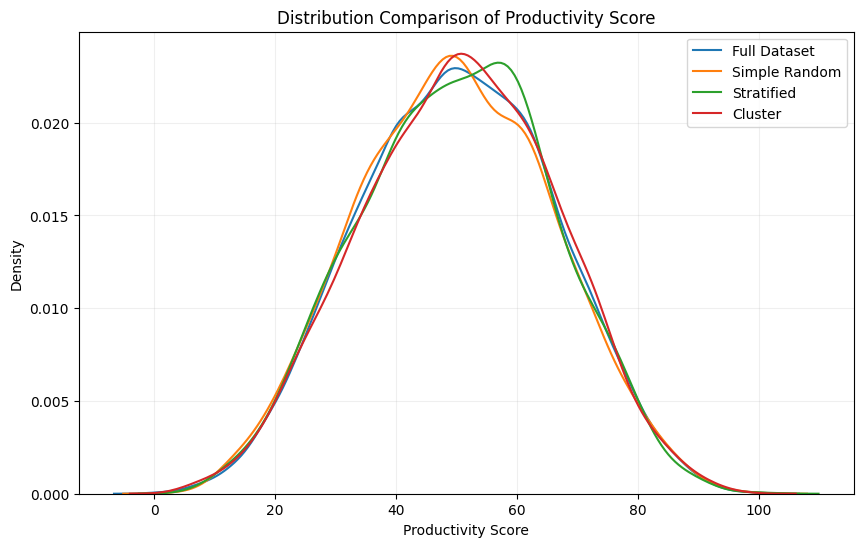

In [90]:
plt.figure(figsize=(10, 6))

sns.kdeplot(
    df_lvlC["productivity_score"],
    label="Full Dataset"
)

sns.kdeplot(
    simple_random_sample["productivity_score"],
    label="Simple Random"
)

sns.kdeplot(
    stratified_sample["productivity_score"],
    label="Stratified"
)

sns.kdeplot(
    cluster_sample["productivity_score"],
    label="Cluster"
)

plt.xlabel("Productivity Score")
plt.ylabel("Density")
plt.title("Distribution Comparison of Productivity Score")
plt.legend()
plt.grid(alpha=0.2)

plt.show()

In [91]:
#Impact on Outlier Detection
def count_outliers(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = data[
        (data[column] < lower_bound) |
        (data[column] > upper_bound)
    ]

    return len(outliers)

outliers = {
    "Full Dataset": count_outliers(
        df_lvlC, "productivity_score"
    ),

    "Simple Random": count_outliers(
        simple_random_sample,
        "productivity_score"
    ),

    "Stratified": count_outliers(
        stratified_sample,
        "productivity_score"
    ),

    "Cluster": count_outliers(
        cluster_sample,
        "productivity_score"
    )
}

print("Number of outliers:")
print(outliers)

Number of outliers:
{'Full Dataset': 18, 'Simple Random': 1, 'Stratified': 1, 'Cluster': 1}


## Analytical Report: Sampling Methods Comparison

**1. Distribution preservation:** Stratified sampling preserved the distribution best, since it draws 10% from each gender group, keeping proportions matched to the population. Simple random sampling was close behind — unbiased in expectation, but small samples can still drift. Cluster sampling, using two combined age_group + stress_group clusters, actually tracked the full dataset's mean, median, and variance reasonably well in this run — better than a single-cluster design would have, since combining two clusters reduces the chance that the sample is dominated by one narrow sub-population. That said, cluster sampling remains the least reliable of the three by design: its accuracy depends heavily on which clusters happen to be drawn, and a different random selection could easily land on more homogeneous or unrepresentative clusters.

**2. Outlier Detection Impact**

| Method        | Outliers | Sample size | % of full dataset |
| ------------- | -------: | ----------: | -----------------: |
| Full Dataset  |       18 |       20000 |             100.0% |
| Simple Random |        1 |        2000 |              10.0% |
| Stratified    |        1 |        2000 |              10.0% |
| Cluster       |        1 |        3667 |              18.3% |

The full dataset contains 18 detected outliers, while each sampling method detected only 1 outlier. The lower number in the Simple Random and Stratified samples is mainly caused by their smaller sample size, so some rare extreme values were not included.

Cluster sampling can also affect outlier detection because it includes observations from only the selected clusters. As a result, the distribution within those clusters may differ from the distribution of the full dataset, which can change the IQR boundaries and affect which values are classified as outliers.

**Note on cluster sample size:** unlike Simple Random and Stratified sampling, which were both drawn at an exact 10% fraction (2,000 rows), the cluster sample came out to 3,667 rows — 18.3% of the full dataset, nearly double the target. This is a known limitation of cluster sampling: clusters are naturally unequal in size, so selecting a fixed *number* of clusters does not guarantee a fixed *proportion* of the population. Controlling sample size precisely would require either weighting/adjusting for cluster size when selecting clusters, or sub-sampling within the selected clusters after they are chosen.

**3. Recommendations:**
- Use **stratified sampling** by default when a relevant grouping variable is known — it best preserves population structure.
- Use **simple random sampling** as an unbiased fallback when no clear subgroup exists, but increase sample size if rare/extreme values matter.
- Use **cluster sampling** cautiously — always sample multiple clusters, never one, to avoid the sample being dominated by a single unrepresentative sub-population. Also account for unequal cluster sizes, since the resulting sample fraction can deviate substantially from the intended target.
- Always compute outlier bounds relative to the full population when possible, not within a small/biased sample.
